In [1]:
# TODO: kontrola interpolacji w ROI
# TODO: liczymi ICA i korelujemy z EOG
# TODO: sprawdzenie pętli 1 do 60
# TODO: dlaczego mamy różne liczby epok
# TODO: usuwanie zaszunionych kanałów

# EEG Preprocessing Pipeline

## Overview
This notebook implements a comprehensive EEG preprocessing pipeline using MNE-Python. It processes raw EEG data through multiple stages including filtering, bad channel detection, artifact removal, and epoch extraction.

## Pipeline Steps

1. **Data Loading** - Loads raw EEG files and behavioral/trigger data
2. **Montage Setup** - Configures electrode positions and channel types (EEG, EOG)
3. **Trigger Processing** - Converts triggers to annotations and removes training periods
4. **Signal Cropping** - Trims data to relevant time windows around events
5. **Filtering** - Applies bandpass filter to remove noise and drifts
6. **Bad Channel Detection** - Identifies noisy channels using PyPREP (with optional RANSAC)
7. **Re-referencing** - Sets average reference across all EEG channels
8. **Ocular Artifact Removal** - Removes eye movement artifacts using EOG regression
9. **Channel Interpolation** - Interpolates previously identified bad channels
10. **Epoching** - Segments continuous data into event-locked epochs
11. **Automatic Artifact Rejection** - Uses AutoReject to identify and repair/reject bad epochs

## Key Dependencies

- **MNE-Python** - Core EEG processing library
- **PyPREP** - Bad channel detection
- **AutoReject** - Automated epoch rejection and repair
- **pandas** - Trigger file handling

## Configuration Parameters

All preprocessing parameters are defined in the Configuration section and can be adjusted:
- File paths (input/output directories)
- Electrode montage type
- Filter cutoffs
- Epoch time windows
- AutoReject hyperparameters
- Output options (saving, plotting)

## Output

Preprocessed epochs are saved as FIF files with metadata (participant ID, sex, age) in the filename.

In [2]:
import mne
from mne.preprocessing import EOGRegression
from tqdm import tqdm
from pyprep.find_noisy_channels import NoisyChannels
import os
import sys
import numpy as np
import pandas as pd
from autoreject import AutoReject

from src.load_data import prepare_files_info
from src.utils import write
from src.triggers import set_annotations_from_trigger_file, drop_training_annotations
from src.epochs import create_epochs

# matplotlib.use('TkAgg')
mne.set_log_level('ERROR')

### Configuration

In [3]:
# Paths to data folders
BEH_PATH = "BEH" # Path to the folder with behavioral data files.
EEG_PATH = "EEG" # Path to the folder with raw EEG data files.
RESULT_PATH = "PREPROCESSED" # Path to the folder where preprocessed data will be saved.

# Electrode montage settings
MONTAGE = "biosemi64" # Name of the EEG electrode montage used in the recording (e.g., "biosemi64").

# Signal cropping settings
START_CUT_EXTRA_TIME = 2 # Extra time (in seconds) kept before the first event/trigger.
END_CUT_EXTRA_TIME = 2 # Extra time (in seconds) kept after the last event/trigger.

# Filtering settings
LOW_PASS = 0.5 # High‑pass filter cutoff frequency in Hz (removes very slow drifts).
HIGH_PASS = 48 # Low‑pass filter cutoff frequency in Hz (removes high‑frequency noise).

# Bad channel detection (PyPREP)
RANSAC = True # Whether to use the RANSAC algorithm for robust bad channel detection.
SEED = 42 # Random seed to ensure reproducible results.

# Epoching settings
EPOCHS_LEN = [0, 2] # Epoch time window [tmin, tmax] in seconds relative to event onset.
TRIGGER_TYPE = "experiment_mask" # Type/name of triggers used to create epochs.

# AutoReject settings (automatic artifact rejection for epochs)
INTERPOLATION = [1, 2, 3, 4] # Number of channels to interpolate when repairing bad epochs.
CONSENSUS = None # Consensus percentage for rejecting epochs (None = let AutoReject choose).
METHOD = 'bayesian_optimization' # Strategy for optimizing rejection thresholds.
N_JOBS = 1 # Number of parallel jobs used by AutoReject.
CV = 10 # Number of cross‑validation folds used by AutoReject.

# ROI
ROI = {"frontal": ["AFz", "Fz", "FCz", "F1", "F2", "FC1", "FC2"],
       "posterior": ["CPz", "Pz", "POz", "P1", "P2"]}

# Output and visualization settings
SAVE_DATA = True # If True, save preprocessed epochs to disk as FIF files.
OVERWRITE_DATA = True
WRITE_INFO = True # If True, print textual progress and summary information.
PLOT_INFO = True # If True, show diagnostic plots (e.g., rejected epochs, reject_log).

### Parameters

In [4]:
DATA = prepare_files_info(eeg_path=EEG_PATH, beh_path=BEH_PATH)

### Preprocessing

  0%|          | 0/30 [00:00<?, ?it/s]

ET0102
bad channels: ['PO3', 'P1', 'P2', 'POz', 'Pz']
interpolated 5 channels
Created 75 epochs (2.000 s) for 'experiment_mask'
ROI: frontal
Number of epochs: 67
Number of rejected epochs: 8


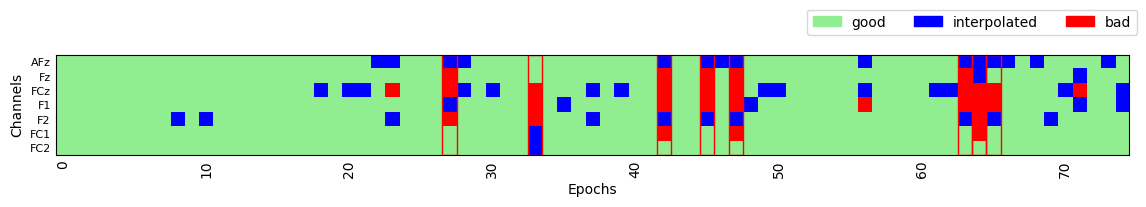

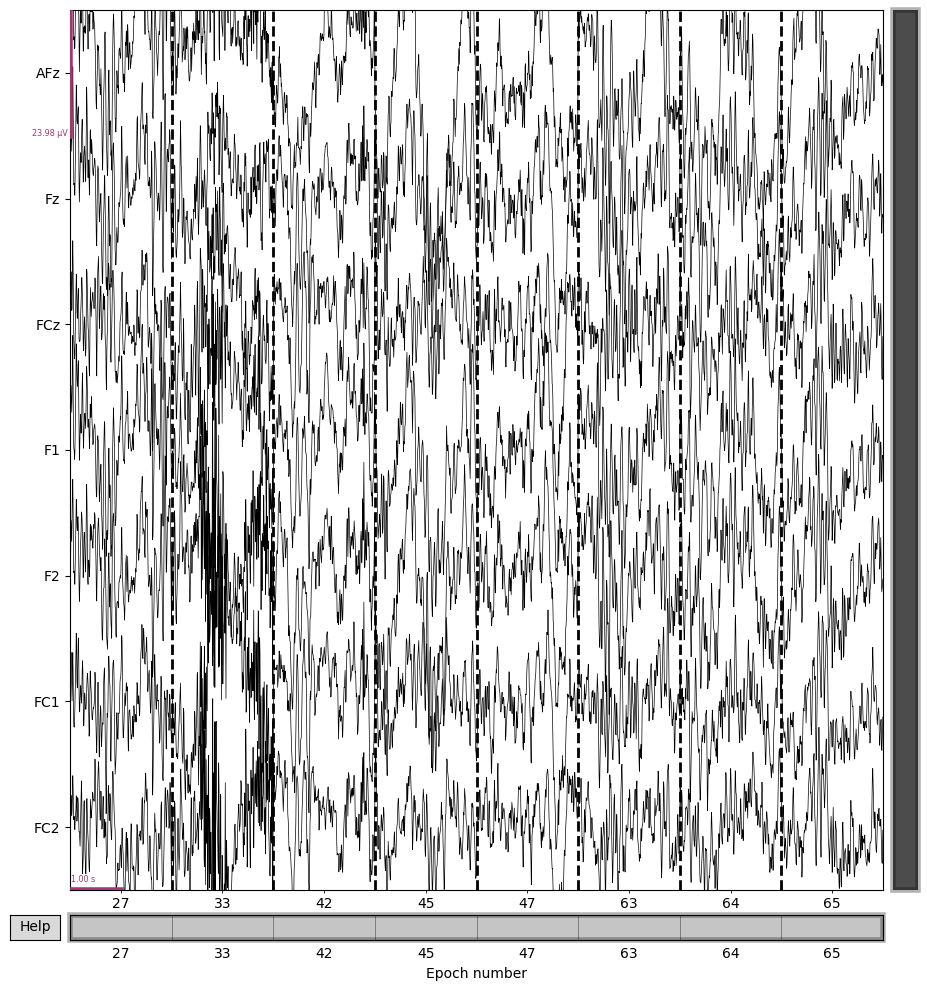

Data saved to ET0102_F_22_preprocessed-epo.fif
ROI: posterior
Number of epochs: 64
Number of rejected epochs: 11


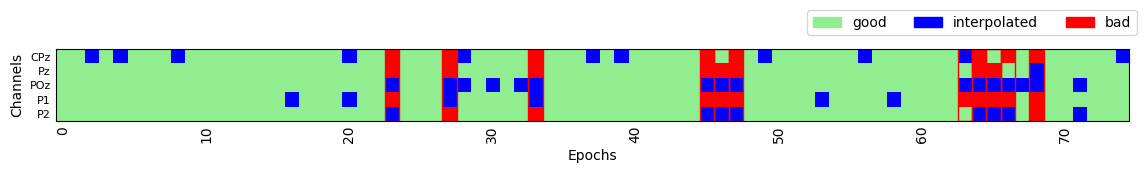

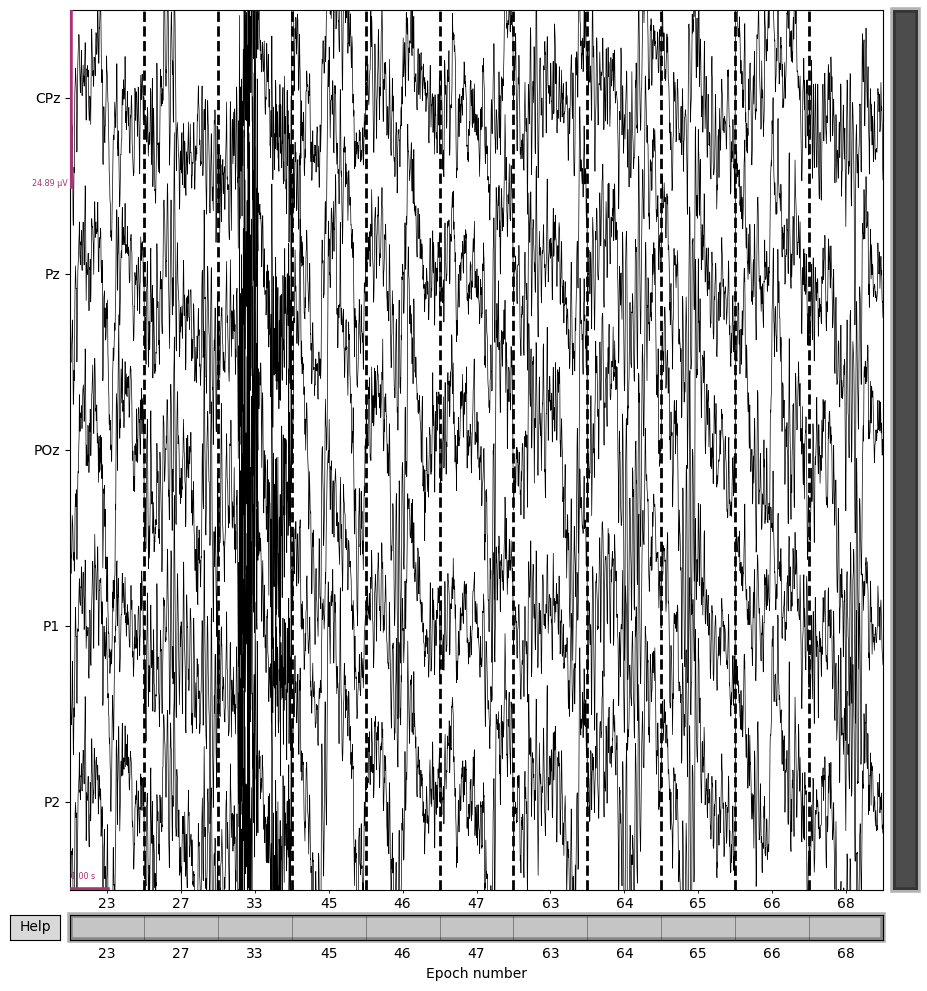

Data saved to ET0102_F_22_preprocessed-epo.fif


  3%|▎         | 1/30 [01:25<41:30, 85.87s/it]

FZ0107
bad channels: ['PO3', 'P5', 'P1', 'POz']
interpolated 4 channels
Created 75 epochs (2.000 s) for 'experiment_mask'
ROI: frontal
Number of epochs: 73
Number of rejected epochs: 2


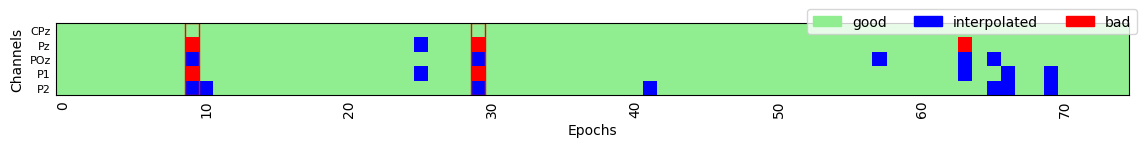

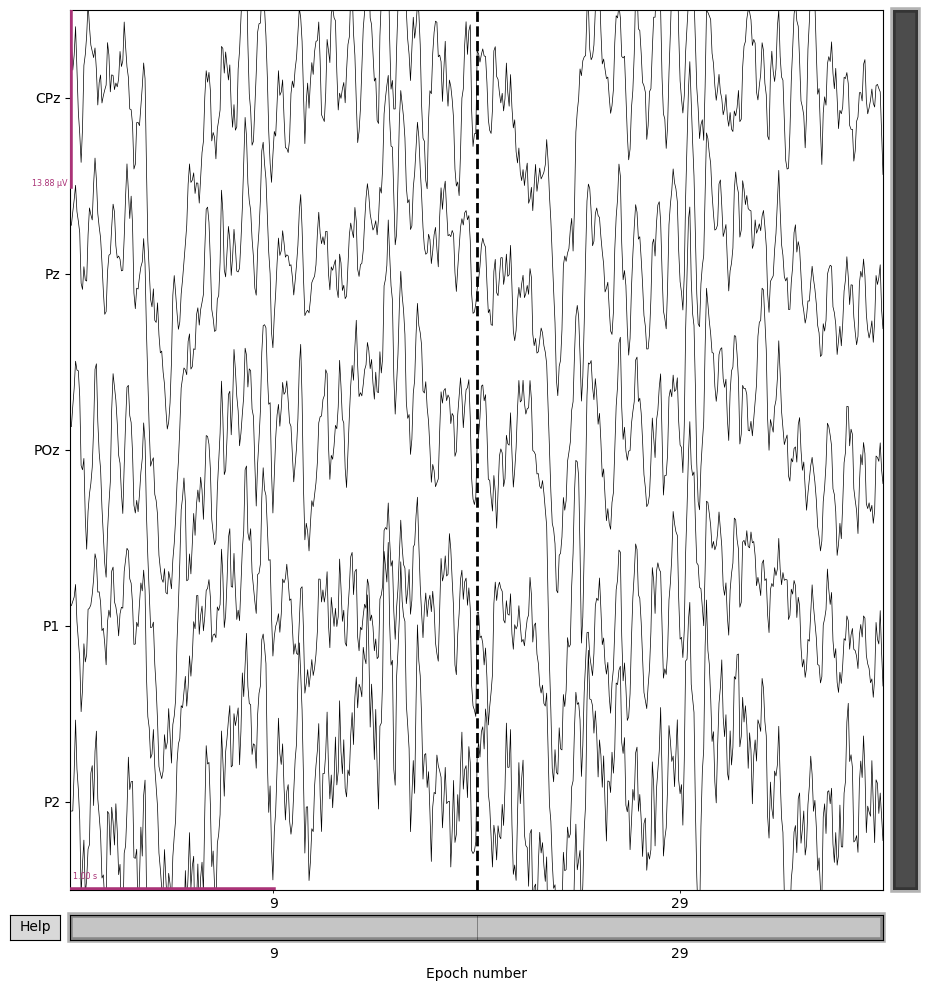

Data saved to FZ0107_M_19_preprocessed-epo.fif


  7%|▋         | 2/30 [02:53<40:36, 87.03s/it]

GK2402
Number of epochs: 71
Number of rejected epochs: 4


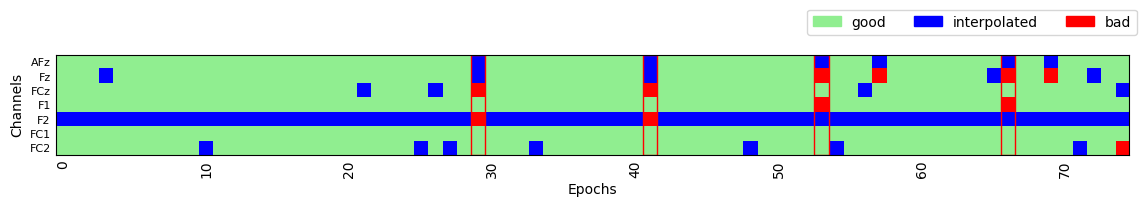

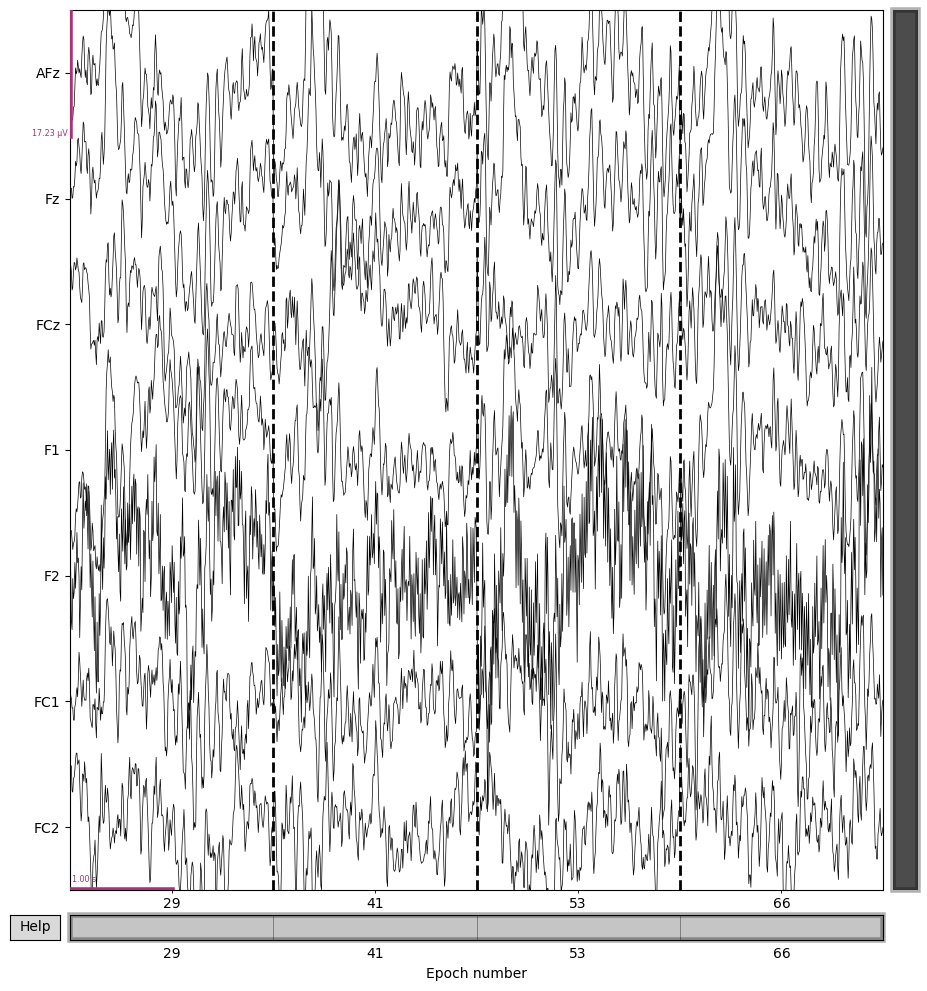

Data saved to FZ0107_M_19_preprocessed-epo.fif
ROI: posterior
bad channels: ['P1', np.str_('Pz'), 'P2', 'P3']
interpolated 4 channels
Created 75 epochs (2.000 s) for 'experiment_mask'
ROI: frontal
Number of epochs: 75
Number of rejected epochs: 0


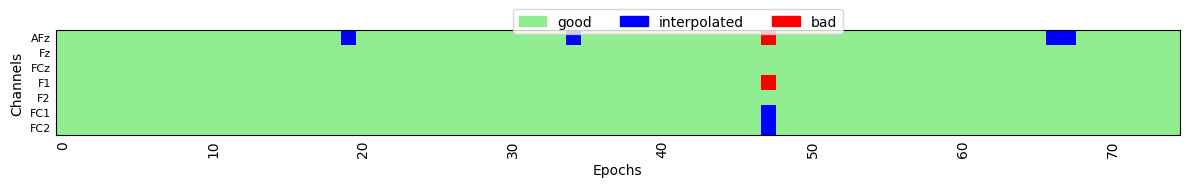

Data saved to GK2402_F_20_preprocessed-epo.fif
ROI: posterior
Number of epochs: 75
Number of rejected epochs: 0


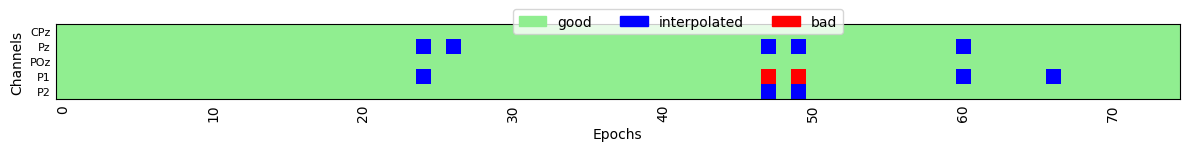

Data saved to GK2402_F_20_preprocessed-epo.fif


 10%|█         | 3/30 [04:14<37:53, 84.20s/it]

GL1210
bad channels: [np.str_('P1'), np.str_('FT7'), 'P2', 'Pz', np.str_('POz'), np.str_('T7')]
interpolated 6 channels
Created 75 epochs (2.000 s) for 'experiment_mask'
ROI: frontal
Number of epochs: 74
Number of rejected epochs: 1


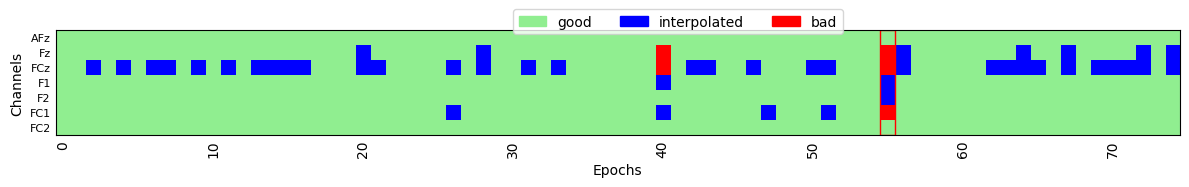

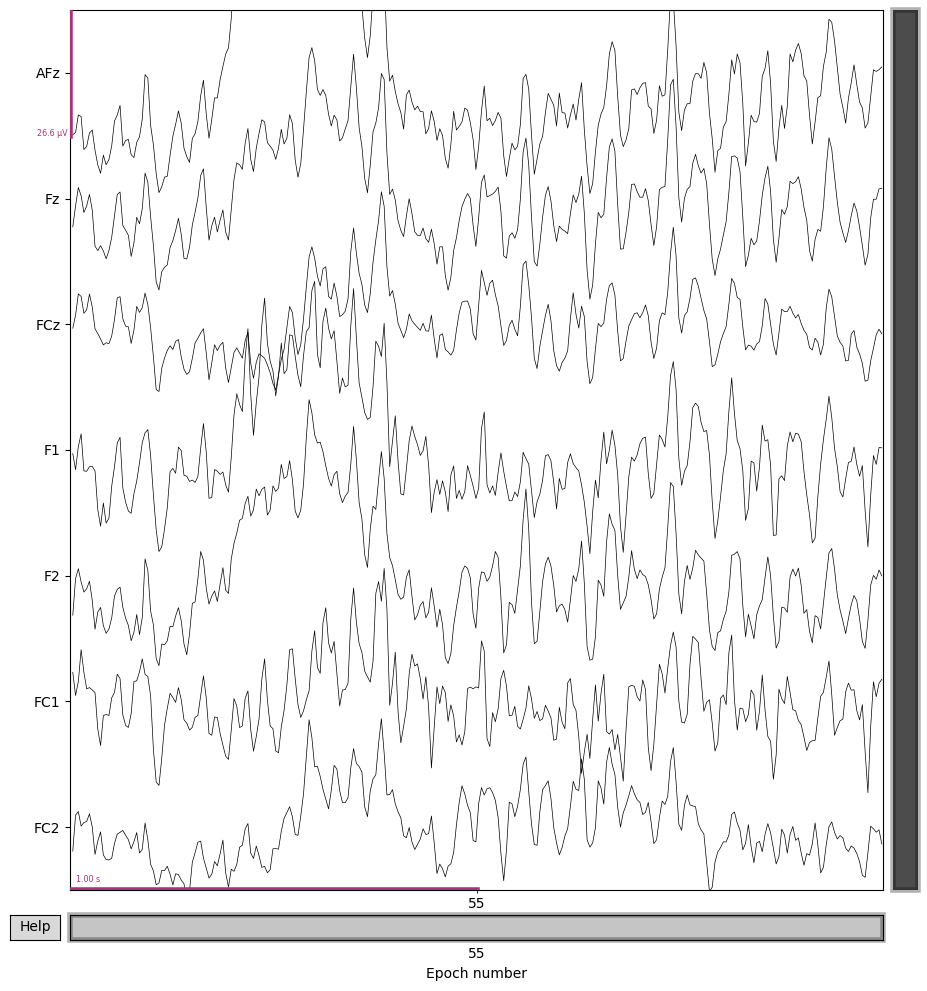

Data saved to GL1210_F_20_preprocessed-epo.fif
ROI: posterior
Number of epochs: 75
Number of rejected epochs: 0


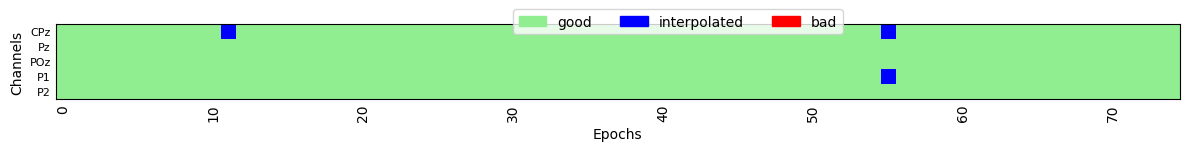

Data saved to GL1210_F_20_preprocessed-epo.fif


 13%|█▎        | 4/30 [05:38<36:24, 84.01s/it]

GL2007
bad channels: [np.str_('Pz'), 'P1', 'POz', 'P2']
interpolated 4 channels
Created 75 epochs (2.000 s) for 'experiment_mask'
ROI: frontal
Number of epochs: 74
Number of rejected epochs: 1


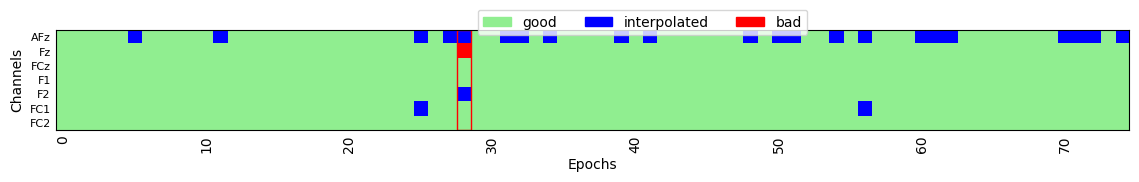

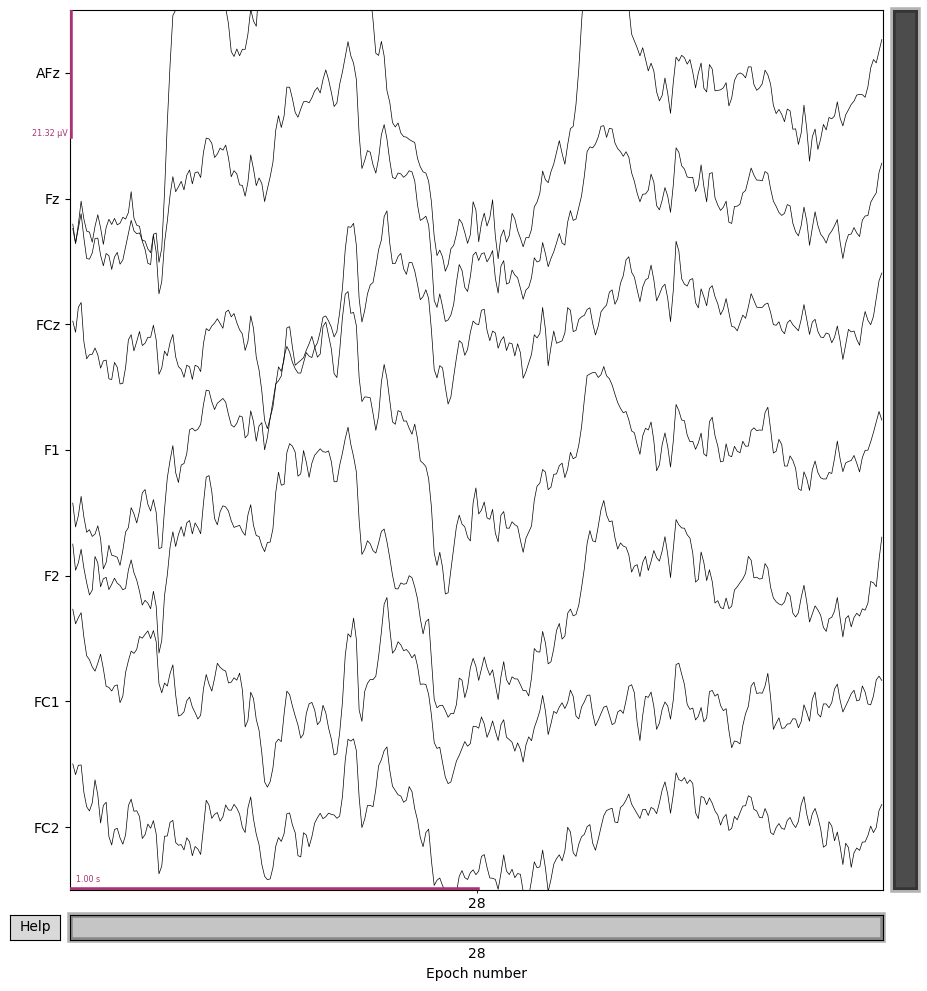

Data saved to GL2007_F_19_preprocessed-epo.fif
ROI: posterior
Number of epochs: 73
Number of rejected epochs: 2


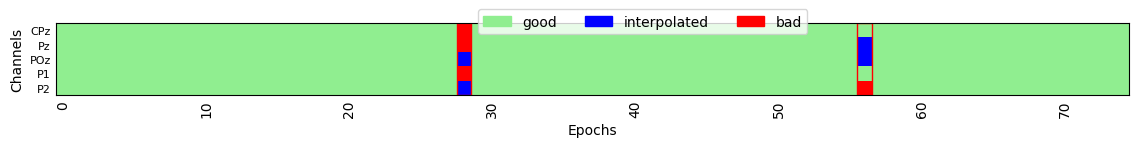

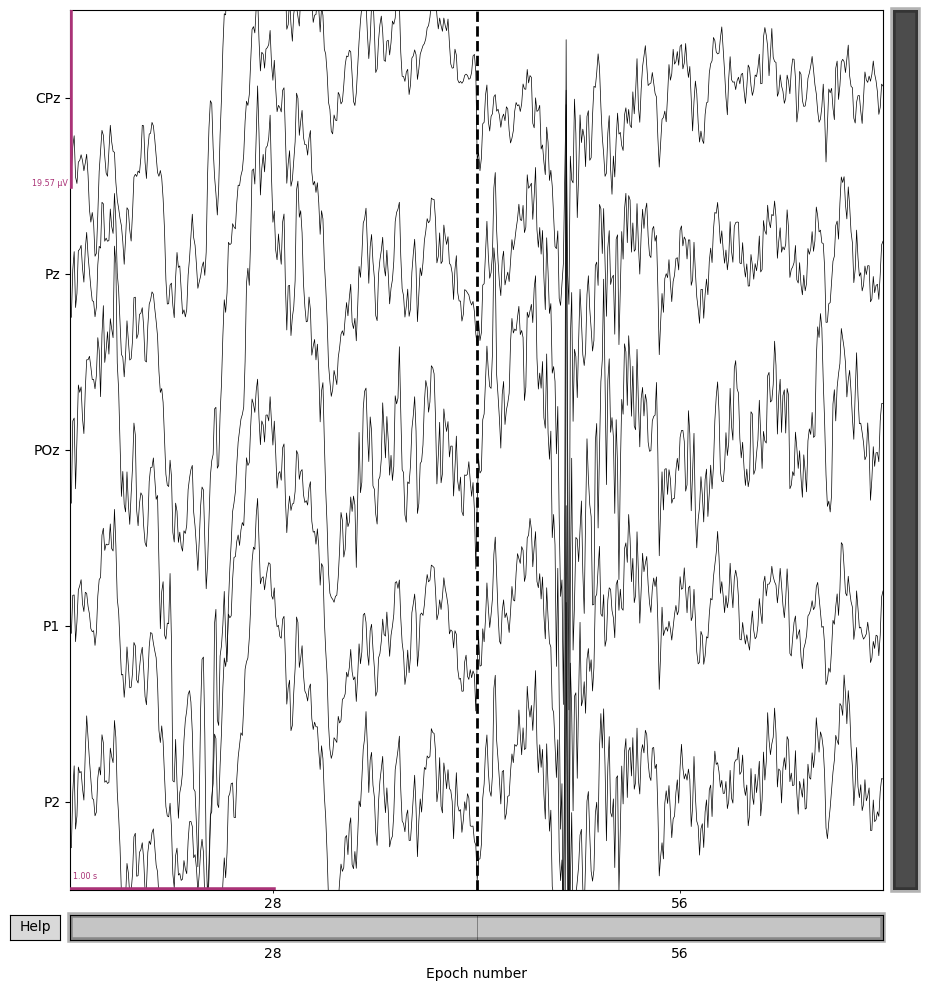

Data saved to GL2007_F_19_preprocessed-epo.fif


 17%|█▋        | 5/30 [06:52<33:34, 80.56s/it]

GW0407
bad channels: ['P1', 'P2', 'Pz', np.str_('POz'), np.str_('P3')]
interpolated 5 channels
Created 75 epochs (2.000 s) for 'experiment_mask'
ROI: frontal
Number of epochs: 70
Number of rejected epochs: 5


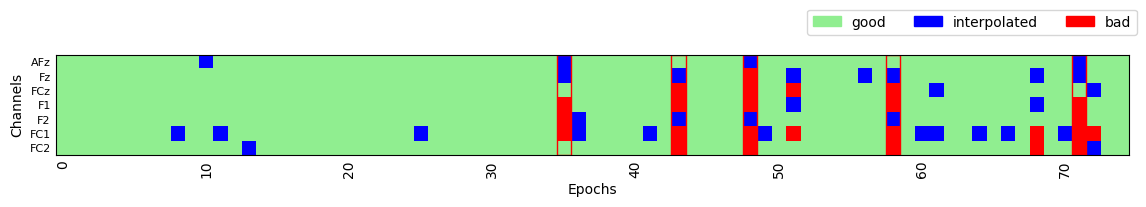

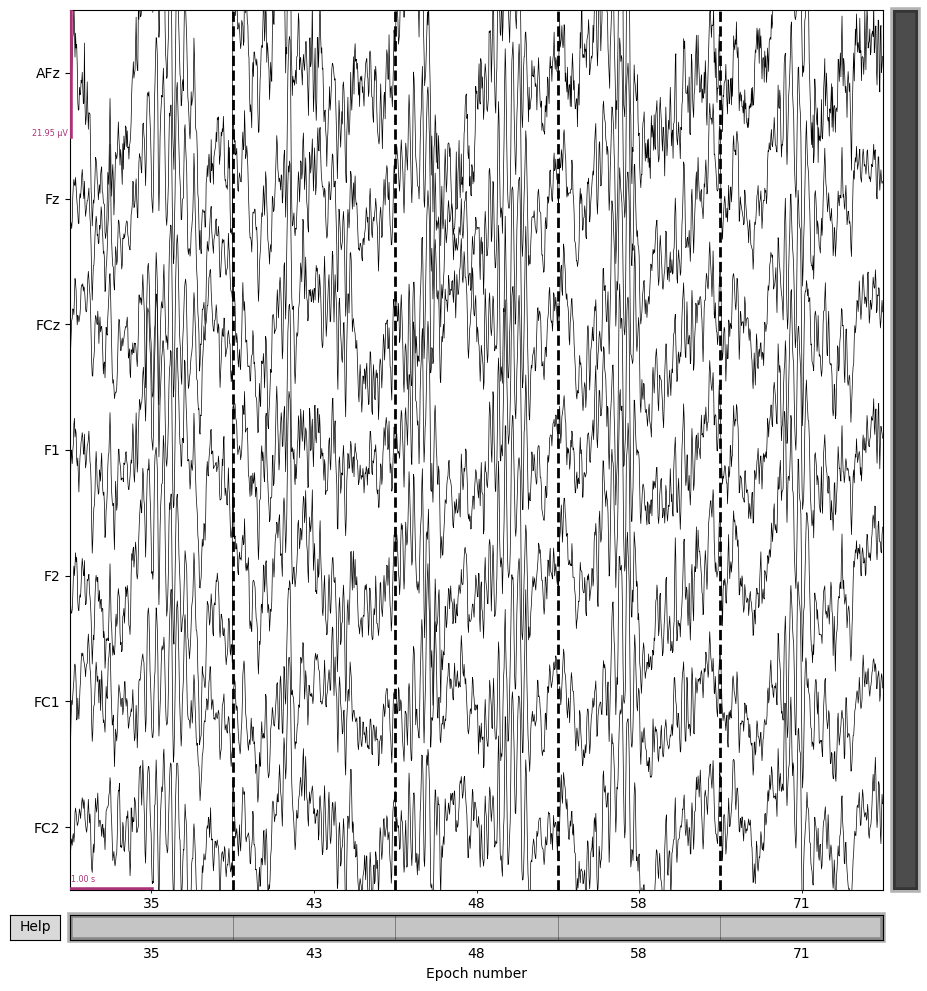

Data saved to GW0407_F_20_preprocessed-epo.fif
ROI: posterior
Number of epochs: 69
Number of rejected epochs: 6


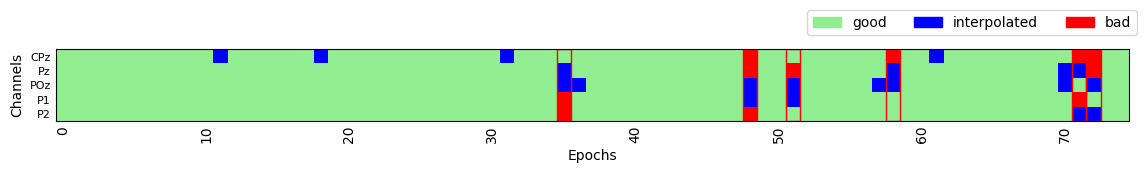

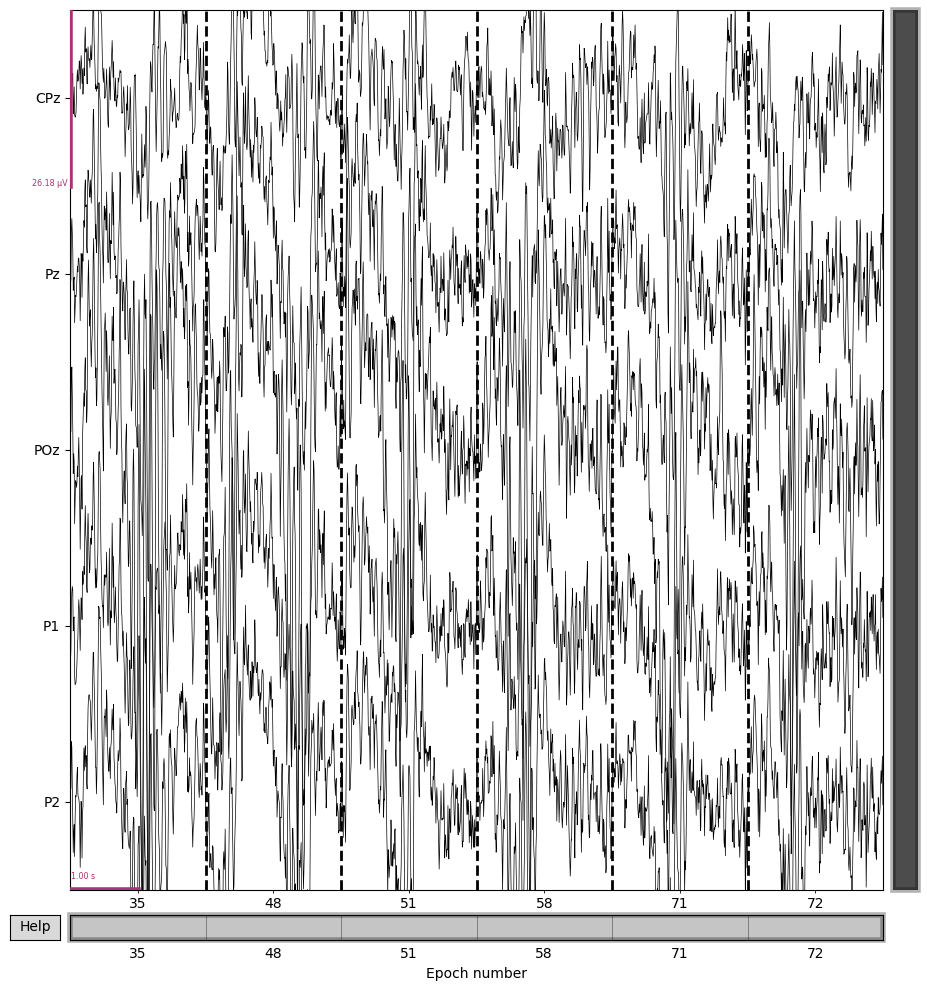

Data saved to GW0407_F_20_preprocessed-epo.fif


 20%|██        | 6/30 [08:06<31:16, 78.19s/it]

GZ1103
bad channels: ['Iz', 'P1', np.str_('CP4')]
interpolated 3 channels
Created 75 epochs (2.000 s) for 'experiment_mask'
ROI: frontal
Number of epochs: 75
Number of rejected epochs: 0


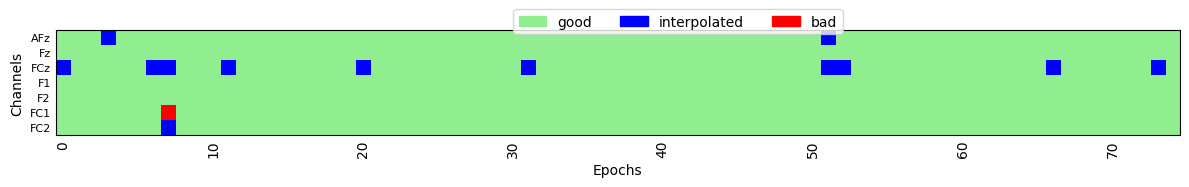

Data saved to GZ1103_F_27_preprocessed-epo.fif
ROI: posterior
Number of epochs: 75
Number of rejected epochs: 0


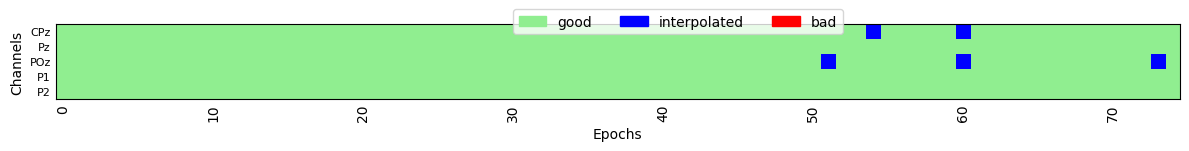

Data saved to GZ1103_F_27_preprocessed-epo.fif


 23%|██▎       | 7/30 [09:20<29:29, 76.94s/it]

HB0712
bad channels: ['Pz', 'P1', 'POz', 'P2']
interpolated 4 channels
Created 75 epochs (2.000 s) for 'experiment_mask'
ROI: frontal
Number of epochs: 68
Number of rejected epochs: 7


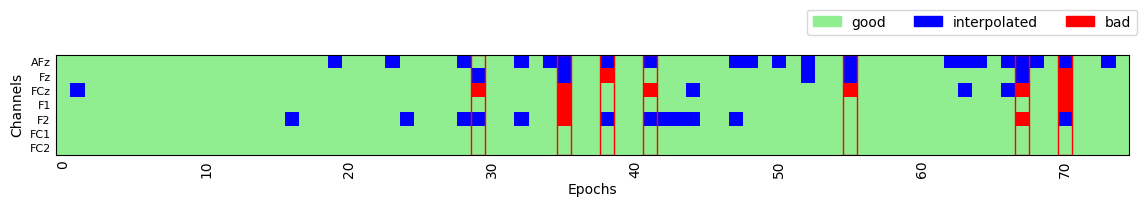

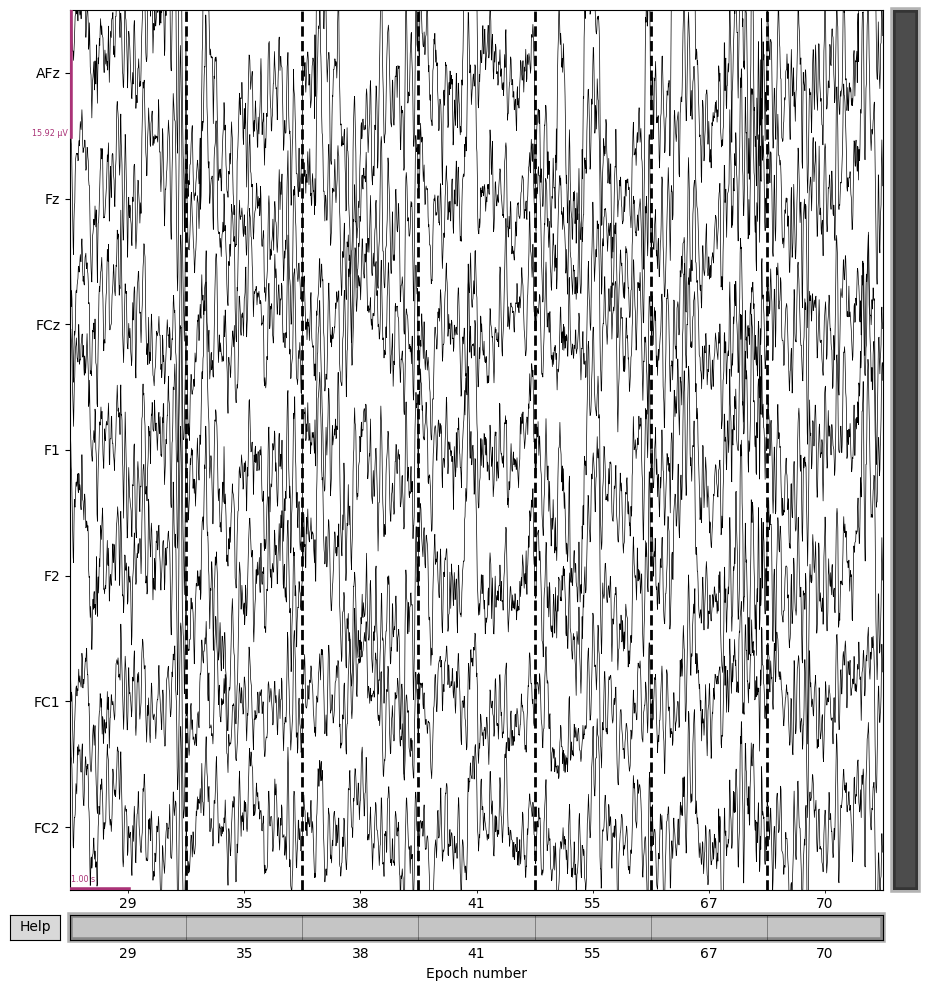

Data saved to HB0712_F_20_preprocessed-epo.fif
ROI: posterior
Number of epochs: 74
Number of rejected epochs: 1


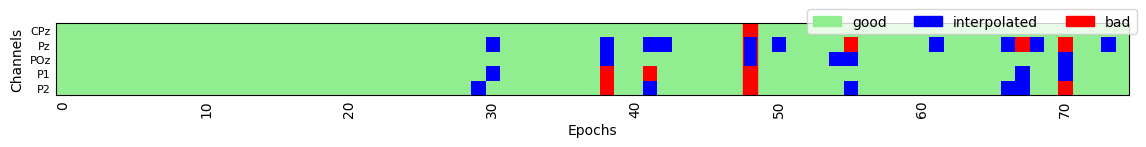

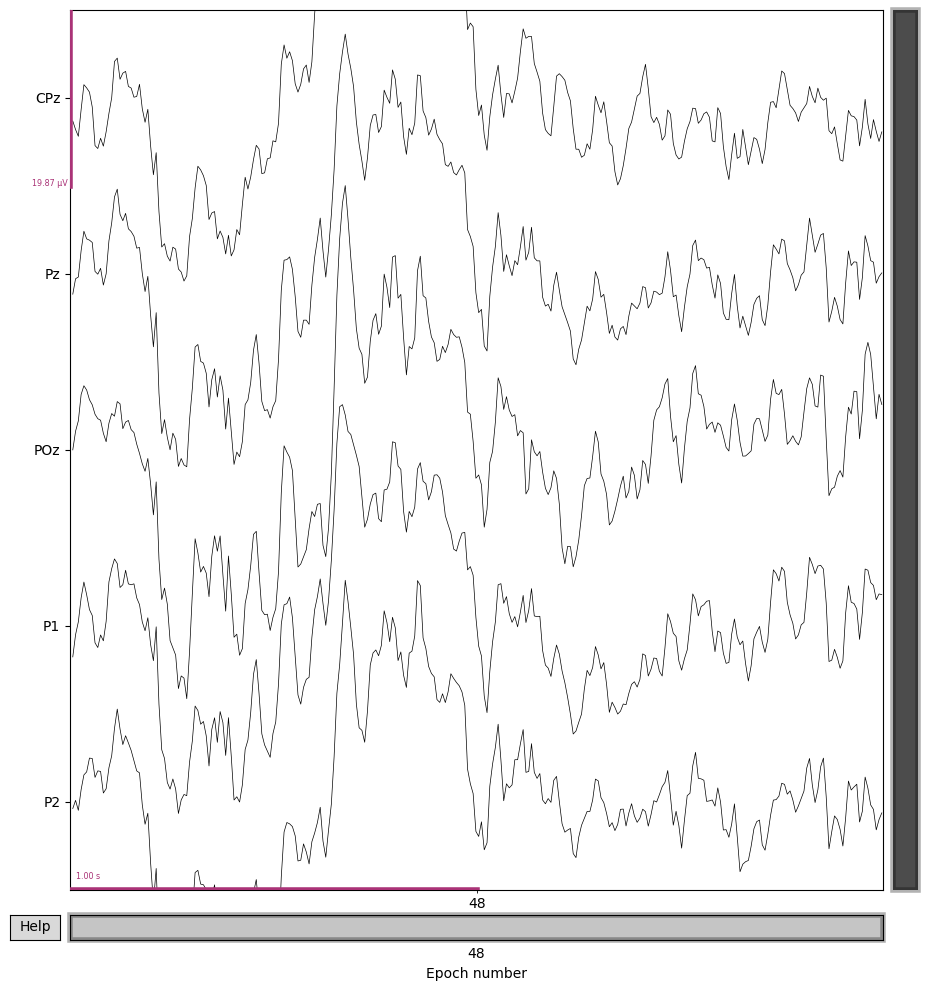

Data saved to HB0712_F_20_preprocessed-epo.fif


 27%|██▋       | 8/30 [10:56<30:26, 83.02s/it]

HP1505
bad channels: ['Oz', np.str_('POz'), 'O2', 'PO3']
interpolated 4 channels
Created 75 epochs (2.000 s) for 'experiment_mask'
ROI: frontal
Number of epochs: 74
Number of rejected epochs: 1


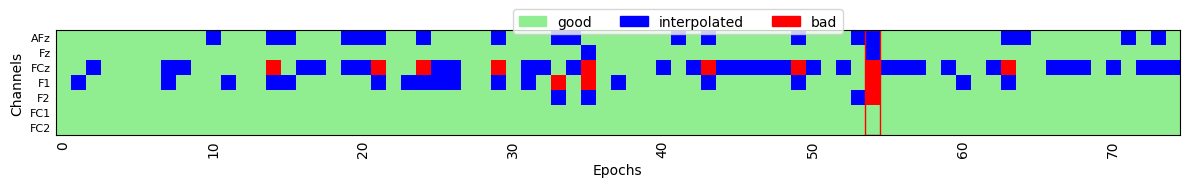

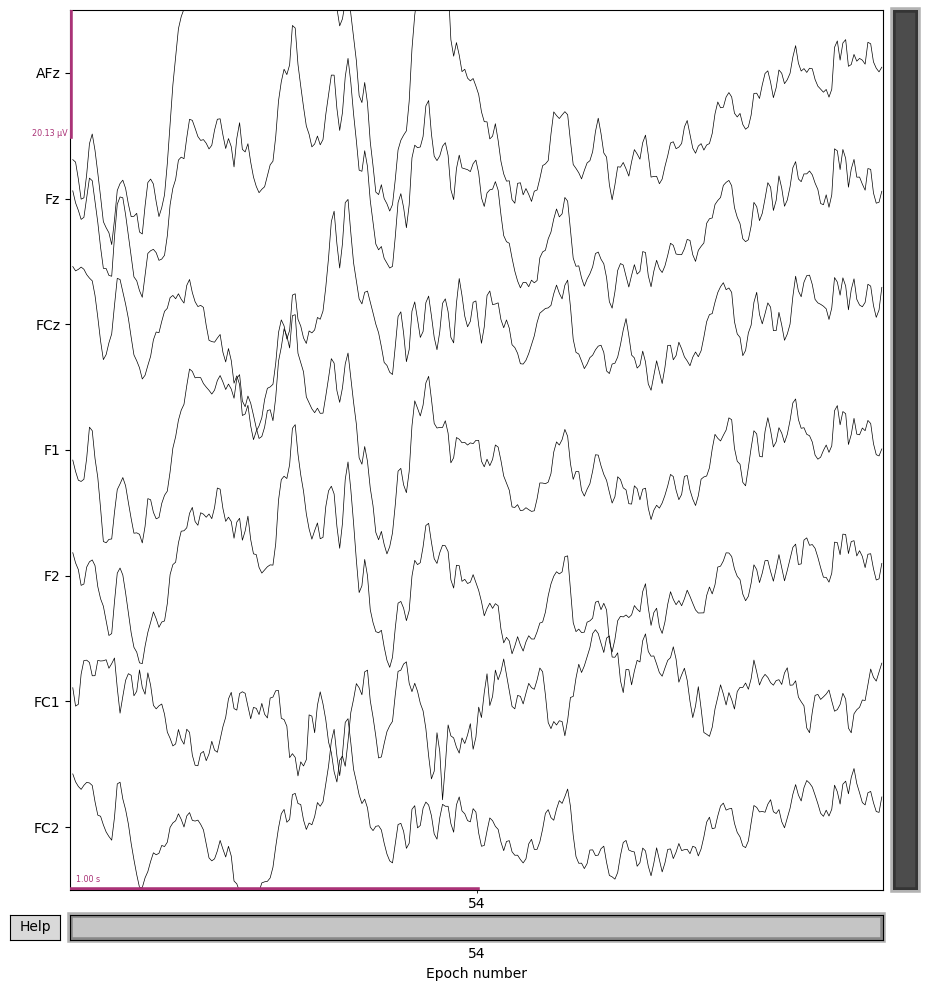

Data saved to HP1505_M_23_preprocessed-epo.fif
ROI: posterior
Number of epochs: 74
Number of rejected epochs: 1


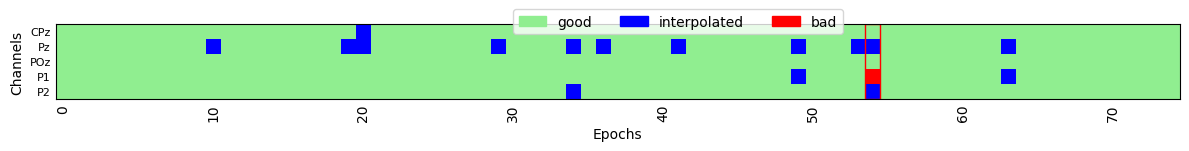

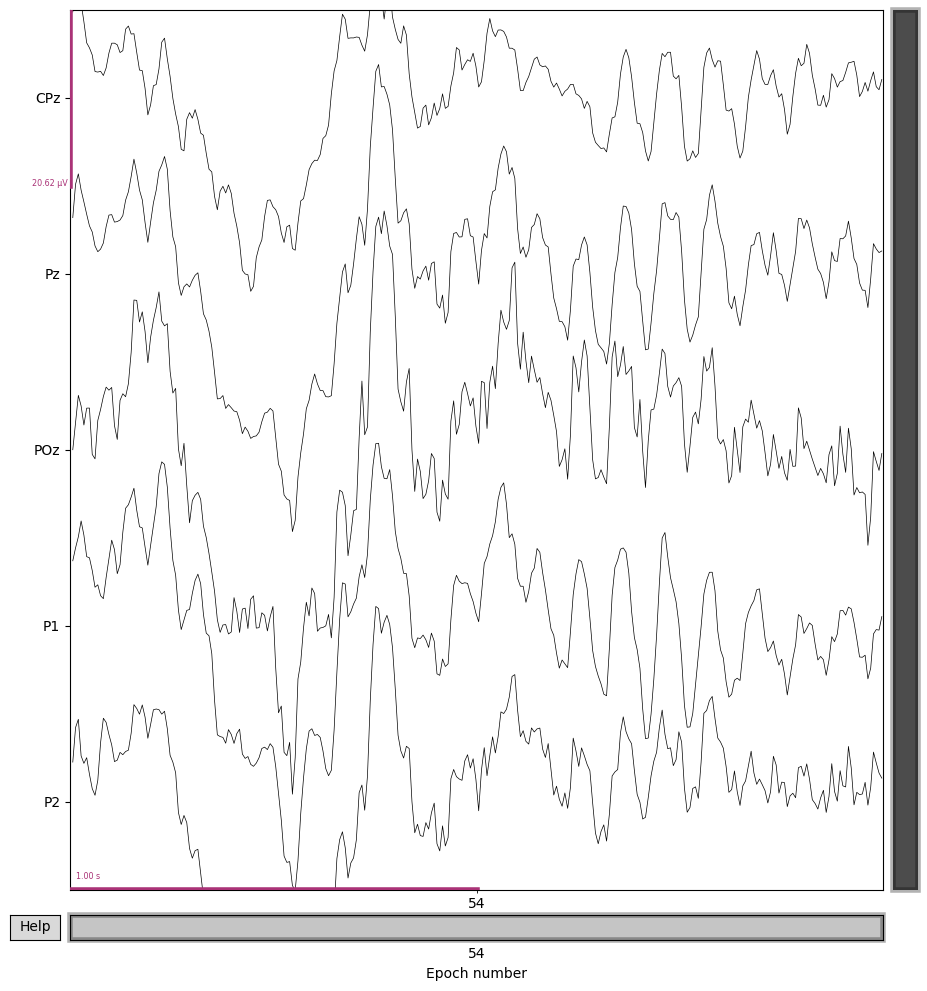

Data saved to HP1505_M_23_preprocessed-epo.fif


 30%|███       | 9/30 [12:15<28:35, 81.71s/it]

HZ1304
bad channels: ['PO3', 'P1', 'P2', 'P3']
interpolated 4 channels
Created 75 epochs (2.000 s) for 'experiment_mask'
ROI: frontal
Number of epochs: 71
Number of rejected epochs: 4


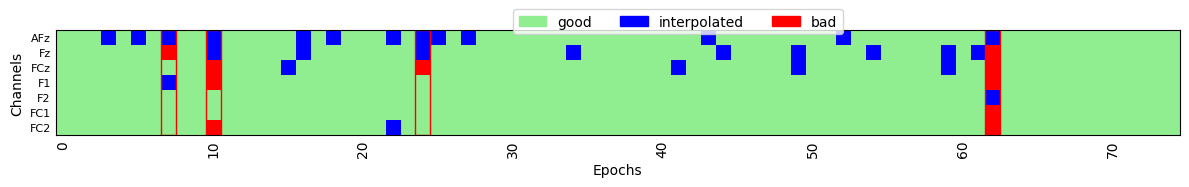

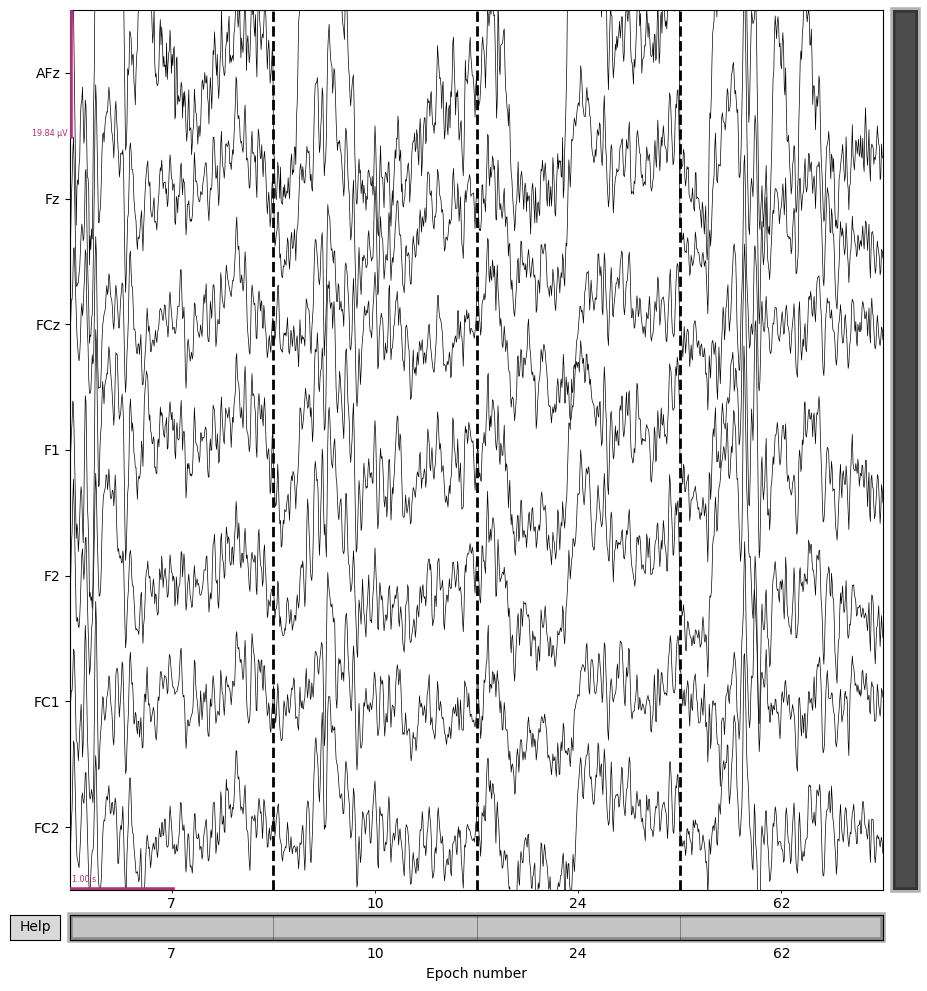

Data saved to HZ1304_F_29_preprocessed-epo.fif
ROI: posterior
Number of epochs: 72
Number of rejected epochs: 3


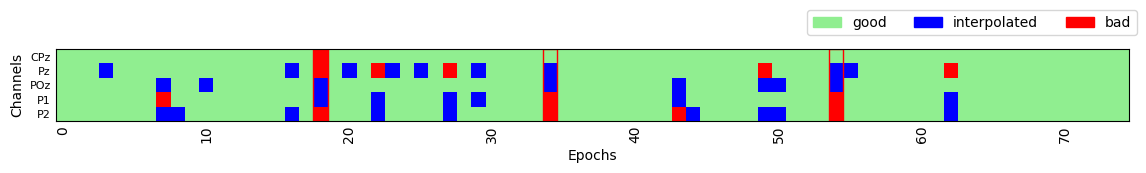

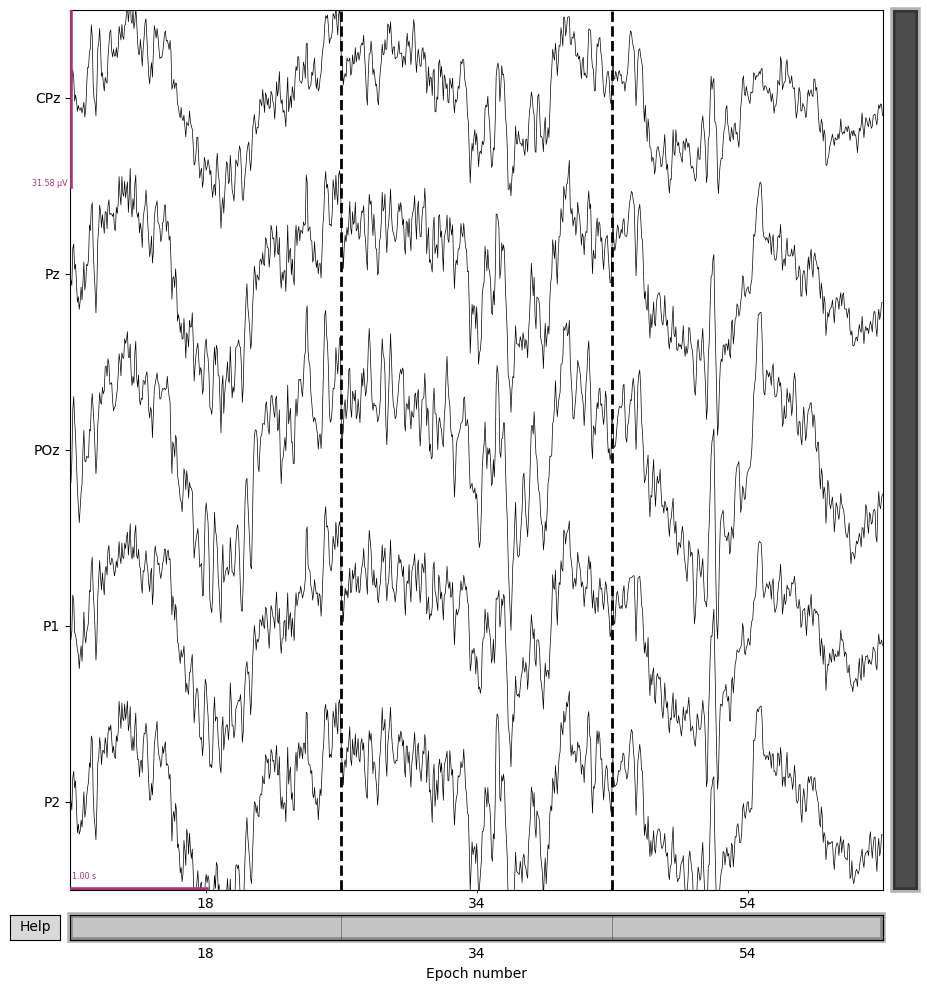

Data saved to HZ1304_F_29_preprocessed-epo.fif


 33%|███▎      | 10/30 [13:34<26:54, 80.72s/it]

IZ2310
bad channels: ['PO3', 'P1', 'POz', 'P3']
interpolated 4 channels
Created 75 epochs (2.000 s) for 'experiment_mask'
ROI: frontal


 33%|███▎      | 10/30 [14:27<28:55, 86.77s/it]


KeyboardInterrupt: 

In [5]:
for part in tqdm(DATA):
    write(part['ID'], WRITE_INFO)
    file_name = f"{part['ID']}_{part['sex']}_{part['age']}_preprocessed-epo.fif"
    if not OVERWRITE_DATA and file_name in os.listdir(RESULT_PATH):
        write("File already exists", WRITE_INFO)
        continue
    # --- load eeg ---
    raw = mne.io.read_raw(part['eeg_file'], preload=True, verbose=False)
    trigg_df = pd.read_csv(part['trigg_file'], comment='#')

    # --- montage ---
    eog_channels = {f'EXG{i}': 'eog' for i in range(1, 5) if f'EXG{i}' in raw.ch_names}
    if eog_channels:
        raw.set_channel_types(eog_channels)
    drop_channels = [f'EXG{i}' for i in range(5, 9) if f'EXG{i}' in raw.ch_names]
    if drop_channels:
        raw.drop_channels(drop_channels)
    raw.set_montage(MONTAGE, on_missing='warn')

    # --- change triggers to annotation and rename them
    raw = set_annotations_from_trigger_file(raw, trigg_df, write_info=WRITE_INFO)
    if raw is None:
        sys.stdout.flush() # for correct order of printed text when using tqdm
        continue

    # --- remove training ---
    raw = drop_training_annotations(raw)

    # --- crop signal ---
    times = raw.annotations.onset
    start_cut = max(0, times[0] - START_CUT_EXTRA_TIME)
    end_cut = min(raw.times[-1], times[-1] + END_CUT_EXTRA_TIME)
    raw.crop(start_cut, end_cut)
    #raw.annotations.onset -= start_cut

    # --- filter ---
    raw.filter(l_freq=LOW_PASS, h_freq=HIGH_PASS, picks="eeg", verbose=False)

    # --- find and mark bad channels ---
    nc = NoisyChannels(raw, ransac=RANSAC, do_detrend=False, random_state=SEED)
    nc.find_all_bads()
    raw.info['bads'] = nc.get_bads()
    write(f"bad channels: {raw.info['bads']}", WRITE_INFO)

    # --- set reference ---
    raw.set_eeg_reference("average", verbose=False)

    # --- remove ocular artifacts ---
    model_plain = EOGRegression(picks="eeg", exclude="bads", picks_artifact="eog").fit(raw)
    raw = model_plain.apply(raw, copy=True)

    # --- interpolate bad channels ---
    if len(raw.info['bads']) > 0:
        raw.interpolate_bads(reset_bads=True, verbose=False)
        write(f"interpolated {len(nc.get_bads())} channels", WRITE_INFO)

    # --- create epochs ---
    epochs_all = create_epochs(raw, trigger_type=TRIGGER_TYPE, tmin=EPOCHS_LEN[0],
                               tmax=EPOCHS_LEN[1], write_info=WRITE_INFO)

    for roi, electrodes in ROI.items():
        write(f"ROI: {roi}", WRITE_INFO)
        epochs = epochs_all.copy().pick(electrodes)
        # epochs = epochs_all[electrodes]
        # epochs.pick_channels(roi)
        # epochs.resample(256)
        if PLOT_INFO:
            epochs_original = epochs.copy()

        # --- remove epochs with artifacts ---
        ar = AutoReject(
                n_interpolate=[2],
                consensus=CONSENSUS,
                thresh_method=METHOD,
                n_jobs=N_JOBS,
                cv = CV,
                random_state=SEED,
                verbose=False)

        epochs, reject_log = ar.fit_transform(epochs, return_log=True)
        write(f"Number of epochs: {len(epochs)}", WRITE_INFO)
        write(f"Number of rejected epochs: {reject_log.bad_epochs.sum()}", WRITE_INFO)

        # --- Plot removed epochs ---
        if PLOT_INFO:
            reject_log.plot('horizontal')
            bad_epochs_idx = np.where(reject_log.bad_epochs)[0] # Bad epoch index
            if 0 < len(bad_epochs_idx) < 20:
                epochs_original[bad_epochs_idx].plot(n_epochs=len(bad_epochs_idx),
                                                      n_channels=64,
                                                      scalings='auto',
                                                      title='Removed epochs')

        # --- Save data ---
        if SAVE_DATA:
            epochs.save(os.path.join(f"{RESULT_PATH}_{roi}", file_name), verbose=False, overwrite=True)
            write(f"Data saved to {file_name}", WRITE_INFO)

    sys.stdout.flush() # for correct order of printed text when using tqdm
